# Dos versiones de los datos

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset

transformacion_simple = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

transformacion_aumento = transforms.Compose([
    transforms.RandomResizedCrop(64, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
])

datos_simple = datasets.ImageFolder("../data/tomate", transform=transformacion_simple)
datos_aumento = datasets.ImageFolder("../data/tomate", transform=transformacion_aumento)

generador = torch.Generator().manual_seed(42)
entreno, validacion, prueba = random_split(datos_simple, [0.8, 0.1, 0.1], generator=generador)
entreno_aumento = Subset(datos_aumento, entreno.indices)

cargador_entreno = DataLoader(entreno_aumento, batch_size=32, shuffle=True)
cargador_validacion = DataLoader(validacion, batch_size=32)
cargador_prueba = DataLoader(prueba, batch_size=32)

print(len(entreno_aumento), len(validacion), len(prueba))

12809 1601 1601


# El for pide la misma foto 8 veces

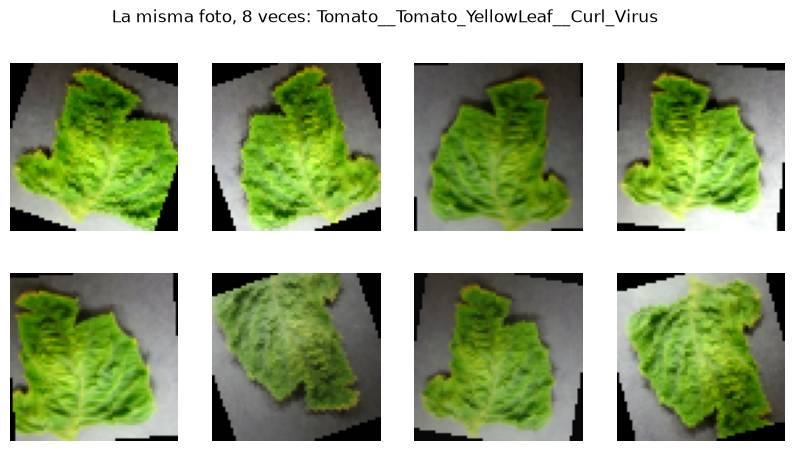

In [2]:
import matplotlib.pyplot as plt

indice = entreno.indices[0]
fig, ejes = plt.subplots(2, 4, figsize=(10, 5))
for eje in ejes.flat:
    imagen, etiqueta = datos_aumento[indice]
    eje.imshow(imagen.permute(1, 2, 0))
    eje.axis("off")
fig.suptitle(f"La misma foto, 8 veces: {datos_simple.classes[etiqueta]}")
plt.show()

In [3]:
import copy
from torch import nn

class RedTomate(nn.Module):
    def __init__(self):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 10),
        )

    def forward(self, x):
        x = self.extractor(x)
        return self.clasificador(x)


def evaluar(red, cargador):
    red.eval()
    aciertos = 0
    total = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            salida = red(imagenes)
            aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()
            total += len(etiquetas)
    return aciertos / total


torch.manual_seed(42)
red = RedTomate()
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(red.parameters(), lr=0.001)

EPOCAS = 20
historial = []
mejor_validacion = 0
mejores_pesos = None
mejor_epoca = 0

for epoca in range(EPOCAS):
    red.train()
    aciertos = 0
    for imagenes, etiquetas in cargador_entreno:
        salida = red(imagenes)
        perdida = criterio(salida, etiquetas)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()

    exactitud_entreno = aciertos / len(entreno_aumento)
    exactitud_validacion = evaluar(red, cargador_validacion)
    historial.append({"epoca": epoca + 1,
                      "entreno": exactitud_entreno,
                      "validacion": exactitud_validacion})
    print(f"Época {epoca + 1}: entreno {exactitud_entreno:.3f}, validación {exactitud_validacion:.3f}")

    if exactitud_validacion > mejor_validacion:
        mejor_validacion = exactitud_validacion
        mejores_pesos = copy.deepcopy(red.state_dict())
        mejor_epoca = epoca + 1

print("Mejor época:", mejor_epoca, "con validación", mejor_validacion)

Época 1: entreno 0.486, validación 0.623
Época 2: entreno 0.661, validación 0.748
Época 3: entreno 0.714, validación 0.757
Época 4: entreno 0.734, validación 0.769
Época 5: entreno 0.748, validación 0.786
Época 6: entreno 0.769, validación 0.749
Época 7: entreno 0.771, validación 0.825
Época 8: entreno 0.782, validación 0.806
Época 9: entreno 0.796, validación 0.809
Época 10: entreno 0.797, validación 0.829
Época 11: entreno 0.807, validación 0.818
Época 12: entreno 0.814, validación 0.833
Época 13: entreno 0.815, validación 0.849
Época 14: entreno 0.824, validación 0.838
Época 15: entreno 0.828, validación 0.849
Época 16: entreno 0.839, validación 0.869
Época 17: entreno 0.832, validación 0.846
Época 18: entreno 0.836, validación 0.876
Época 19: entreno 0.847, validación 0.870
Época 20: entreno 0.847, validación 0.819
Mejor época: 18 con validación 0.8763272954403498


# CURVAS

<Axes: title={'center': 'Exactitud por época, con aumento de datos'}, xlabel='epoca', ylabel='exactitud'>

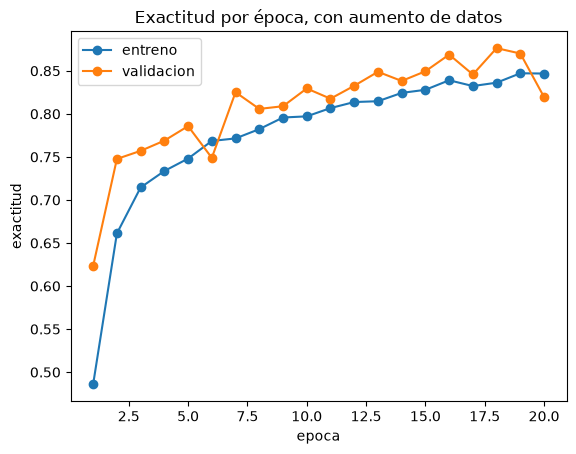

In [4]:
import pandas as pd

curvas = pd.DataFrame(historial)
curvas.plot(x="epoca", y=["entreno", "validacion"], marker="o",
            title="Exactitud por época, con aumento de datos", ylabel="exactitud")

# PRUEBA Y GUARDADO

In [5]:
red.load_state_dict(mejores_pesos)
print("Exactitud en prueba:", evaluar(red, cargador_prueba))

torch.save(mejores_pesos, "../modelos/red_tomate_aumento.pt")

Exactitud en prueba: 0.8775765146783261


# Las dos redes con fotos de internet

In [6]:
from pathlib import Path
from PIL import Image

NOMBRES = [
    "Mancha bacteriana", "Tizón temprano", "Tizón tardío", "Moho de la hoja",
    "Mancha por Septoria", "Arañuela roja", "Mancha diana",
    "Virus del rizado amarillo", "Virus del mosaico", "Hoja sana",
]

red_sin_aumento = RedTomate()
red_sin_aumento.load_state_dict(torch.load("../modelos/red_tomate.pt"))
red_sin_aumento.eval()
red.eval()

def diagnostico(modelo, imagen):
    x = transformacion_simple(imagen).unsqueeze(0)
    with torch.no_grad():
        probabilidades = torch.softmax(modelo(x), dim=1)[0]
    clase = probabilidades.argmax().item()
    return f"{NOMBRES[clase]} ({probabilidades[clase]:.0%})"

for ruta in sorted(Path("../imagenes prueba").iterdir()):
    imagen = Image.open(ruta).convert("RGB")
    print(ruta.name)
    print("   sin aumento:", diagnostico(red_sin_aumento, imagen))
    print("   con aumento:", diagnostico(red, imagen))

0h44fai0vgxe1.jpg
   sin aumento: Tizón temprano (100%)
   con aumento: Arañuela roja (84%)
Common_Diseases_Leaves.jpg
   sin aumento: Tizón temprano (51%)
   con aumento: Tizón tardío (52%)
istockphoto-2239608413-640x640.jpg
   sin aumento: Tizón temprano (70%)
   con aumento: Tizón temprano (95%)
tomate-enfermedad-tizon.jpg
   sin aumento: Tizón tardío (100%)
   con aumento: Tizón temprano (90%)
VRA.jpg
   sin aumento: Tizón tardío (100%)
   con aumento: Tizón tardío (84%)
VRA2.jpg
   sin aumento: Tizón tardío (100%)
   con aumento: Tizón tardío (95%)
